In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
data_dir = "C:\\Users\\Ulyana\\...\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\...\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\...\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 224
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [5]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [6]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_6304\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_6304\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metadata

In [77]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

train_indices = torch.load('Parametr\\train_indices7.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices7.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices7.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [9]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [10]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
1. nevus : tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [11]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [01:49<00:00, 380.86it/s]


In [16]:
from torchvision.models import resnext101_32x4d, ResNeXt101_32X4D_Weights

resnext101_32x4d = models.resnext101_32x4d(weights=ResNeXt101_32X4D_Weights.IMAGENET1K_V2)

class Classification_M(nn.Module):
    def __init__(self):
        super(Classification_M, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_M = Classification_M()    
    
class MultimodalNN(nn.Module):
    def __init__(self):
        super(MultimodalNN, self).__init__()
        
        self.CNN = resnext101_32x4d
        self.outCNN = nn.Linear(1000, num_classes)
        self.meta_net = Classification_M
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img)
        img = self.outCNN(img)
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


NET_deep = MultimodalNN()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext teach\\teacher.pth'
model_weights = torch.load(model_name, device)
NET_deep.load_state_dict(model_weights)
NET_deep = NET_deep.to(device)

NET_deep

MultimodalNN(
  (CNN): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequ

In [17]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


MultimodalNN_light = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\light.pth'
model_weights = torch.load(model_name, device)
MultimodalNN_light.load_state_dict(model_weights)
NET_light = MultimodalNN_light.to(device)

In [18]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


STUD_Model_1 = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext1.pth'
model_weights = torch.load(model_name, device)
STUD_Model_1.load_state_dict(model_weights)
STUD_Model_1 = STUD_Model_1.to(device)

In [19]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


STUD_Model_2 = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext2.pth'
model_weights = torch.load(model_name, device)
STUD_Model_2.load_state_dict(model_weights)
STUD_Model_2 = STUD_Model_2.to(device)

In [20]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


STUD_Model_3 = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext3.pth'
model_weights = torch.load(model_name, device)
STUD_Model_3.load_state_dict(model_weights)
STUD_Model_3 = STUD_Model_3.to(device)

In [21]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


STUD_Model_4 = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext4.pth'
model_weights = torch.load(model_name, device)
STUD_Model_4.load_state_dict(model_weights)
STUD_Model_4 = STUD_Model_4.to(device)

In [22]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


STUD_Model_5 = MultimodalNN_light()

model_name = 'D:\\Python\\Distillation NN\\resnext101_7\\resnext5.pth'
model_weights = torch.load(model_name, device)
STUD_Model_5.load_state_dict(model_weights)
STUD_Model_5 = STUD_Model_5.to(device)

In [23]:
total_params_deep = "{:,}".format(sum(p.numel() for p in NET_deep.parameters()))
print(f"NET_deep параметры: {total_params_deep}")
total_params_light = "{:,}".format(sum(p.numel() for p in NET_light.parameters()))
print(f"NET_light параметры: {total_params_light}")
total_params_light_1 = "{:,}".format(sum(p.numel() for p in STUD_Model_1.parameters()))
print(f"STUD_Model_1 параметры: {total_params_light_1}")
total_params_light_2 = "{:,}".format(sum(p.numel() for p in STUD_Model_2.parameters()))
print(f"STUD_Model_2 параметры: {total_params_light_2}")
total_params_light_3 = "{:,}".format(sum(p.numel() for p in STUD_Model_3.parameters()))
print(f"STUD_Model_3 параметры: {total_params_light_3}")
total_params_light_4 = "{:,}".format(sum(p.numel() for p in STUD_Model_4.parameters()))
print(f"STUD_Model_4 параметры: {total_params_light_4}")
total_params_light_5 = "{:,}".format(sum(p.numel() for p in STUD_Model_5.parameters()))
print(f"STUD_Model_5 параметры: {total_params_light_5}")

NET_deep параметры: 25,041,982
NET_light параметры: 267,686
STUD_Model_1 параметры: 267,686
STUD_Model_2 параметры: 267,686
STUD_Model_3 параметры: 267,686
STUD_Model_4 параметры: 267,686
STUD_Model_5 параметры: 267,686


In [24]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0
    time_outputs2 = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            start_time_outputs = time.time()

            outputs = model(inputs, feats)

            time_outputs = time.time()-start_time_outputs
            time_outputs2 += time_outputs

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print('_' * 60)
    print ('       Время выхода с сети: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_outputs2))))
    print ('       Время выхода с сети в секундах: {:.6f}'.format(time_outputs2))

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN) 

    recall_1 = recall_score(actuals, predictions, average='micro')
    recall_2 = recall_score(actuals, predictions, average='macro')
    

    precision_1 = precision_score(actuals, predictions, average='micro')
    precision_2 = precision_score(actuals, predictions, average='macro')


    f1_1 = f1_score(actuals, predictions, average='micro')
    f1_2 = f1_score(actuals, predictions, average='macro')
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')

    accuracy_1 = accuracy_score(actuals, predictions)

    MCC = matthews_corrcoef(actuals, predictions)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    
    print('_' * 60)
    print('Accuracy score: %.2f' % (accuracy_1*100))
    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('F1: %.4f' % F1)
    print('Matthews corrcoef: %.4f' % MCC)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    
    print('_' * 60)
    print('Recall micro: %.4f' % recall_1)
    print('Recall macro: %.4f' % recall_2)
    print('Precision micro: %.4f' % precision_1)
    print('Precision macro: %.4f' % precision_2)
    print('F1 score micro: %.4f' % f1_1)
    print('F1 score macro: %.4f' % f1_2)
    
    print('Jaccard score micro: %.4f' % jaccard_1)
    print('Jaccard score macro: %.4f' % jaccard_2)
    print('Specificity macro: %.4f' % s1)
    print('Specificity weighted: %.4f' % s3)
    
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

In [80]:
test_1 = test(NET_deep, testloader, device)
print(f"Точность модели-учителя: {test_1:.2f}%")

test_2 = test(NET_light, testloader, device)
print(f"Точность модели-ученика без учителя: {test_2:.2f}%")

test_3 = test(STUD_Model_1, testloader, device)
print(f"Точность модели-ученика со значениями Т=1, alpha=0.5: {test_3:.2f}%")

test_4 = test(STUD_Model_2, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.5: {test_4:.2f}%")

test_5 = test(STUD_Model_3, testloader, device)
print(f"Точность модели-ученика со значениями Т=5, alpha=0.5: {test_5:.2f}%")

test_6 = test(STUD_Model_4, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.25: {test_6:.2f}%")

test_7 = test(STUD_Model_5, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.75: {test_7:.2f}%")

____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.703469
____________________________________________________________
Время тестирования: 00:00:11
Время тестирования в секундах: 11.973957

Точность модели-учителя: 85.18%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.133945
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.594913

Точность модели-ученика без учителя: 76.51%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.128952
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.589946

Точность модели-ученика со значениями Т=1, alpha=0.5: 77.40%
_______________________________

____________________________________________________________
Время тестирования: 00:00:11
Время тестирования в секундах: 11.636773



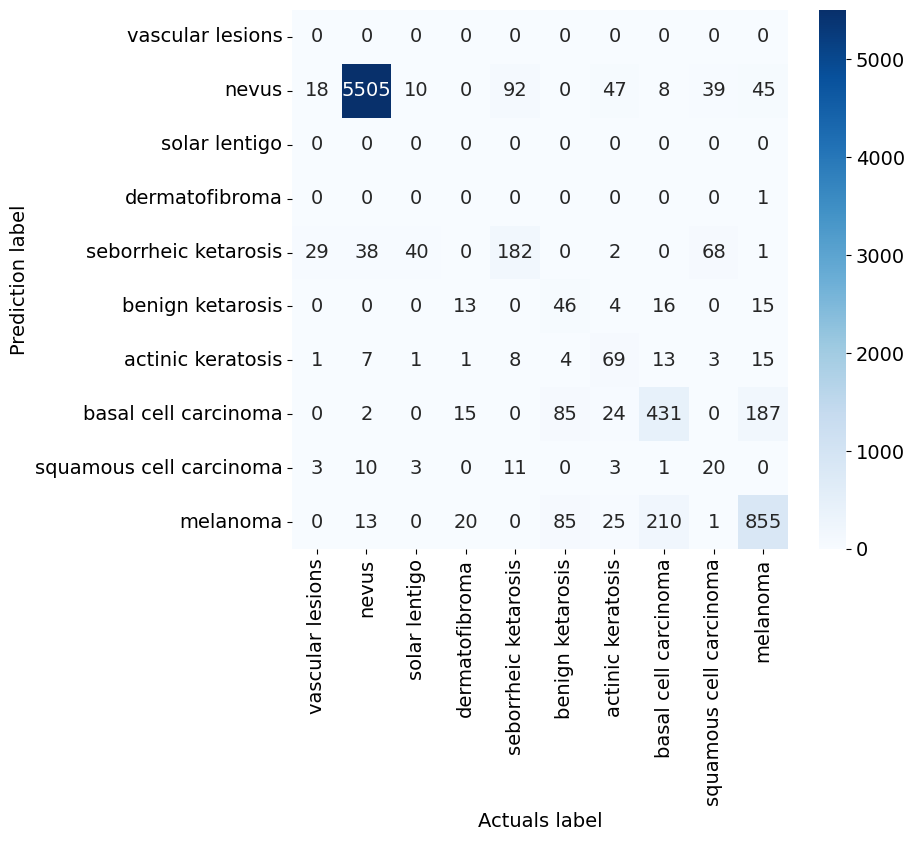

____________________________________________________________
Accuracy score: 85.18
Sensitivity: 0.8518
Specificity: 0.9835
F1: 0.8518
Matthews corrcoef: 0.7104
NPV: 0.9835
PPV: 0.8518
FNR: 0.1482
FPR: 0.0165
____________________________________________________________
Recall micro: 0.8518
Recall macro: 0.3766
Precision micro: 0.8518
Precision macro: 0.4194
F1 score micro: 0.8518
F1 score macro: 0.3848
Jaccard score micro: 0.7418
Jaccard score macro: 0.2944
Specificity macro: 0.9778
Specificity weighted: 0.9265
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.9065
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9999
Specificity none - class seborrheic ketarosis (4): 0.9779
Specificity none - class benign ketarosis (5): 0.9941
Specificity none - class actinic keratosis (6): 0.9935
Specificity none - class basal cell carcinoma (7): 0.9592
Specificity none - class squamous cell carcinoma (8): 0.996

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [82]:
actuals = []
predictions = []

test_NN(NET_deep, testloader)

torch.save(actuals, 'NET_deep\\actuals2.pt')
torch.save(predictions, 'NET_deep\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_deep\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.642077



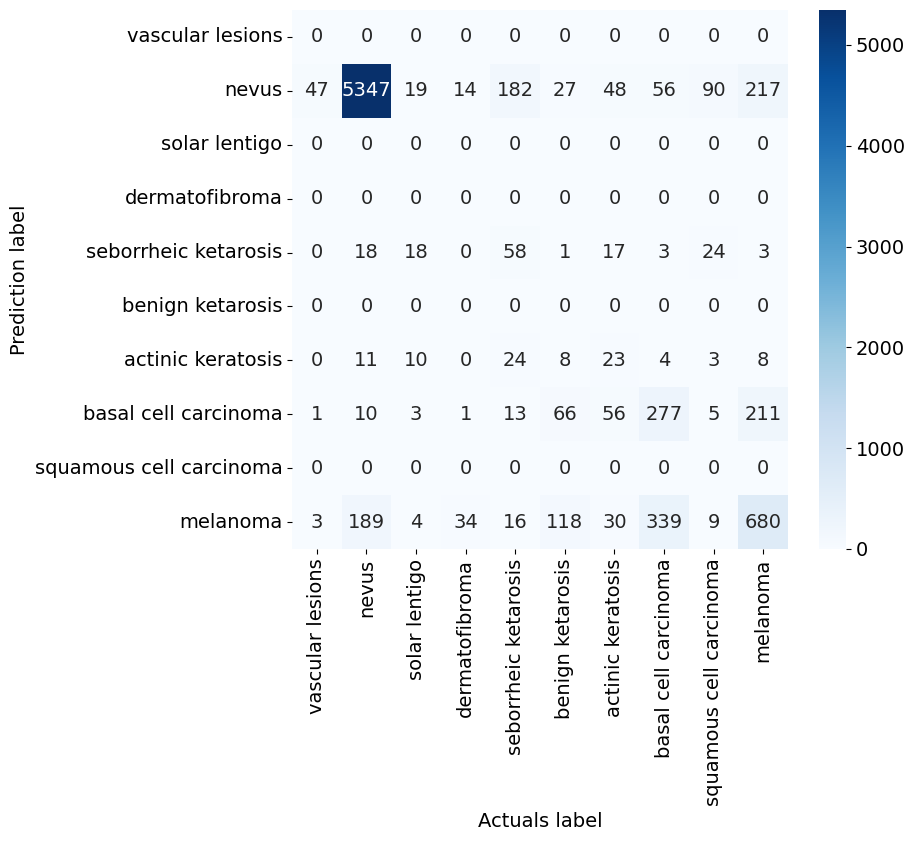

____________________________________________________________
Accuracy score: 76.51
Sensitivity: 0.7651
Specificity: 0.9739
F1: 0.7651
Matthews corrcoef: 0.5220
NPV: 0.9739
PPV: 0.7651
FNR: 0.2349
FPR: 0.0261
____________________________________________________________
Recall micro: 0.7651
Recall macro: 0.2305
Precision micro: 0.7651
Precision macro: 0.2454
F1 score micro: 0.7651
F1 score macro: 0.2315
Jaccard score micro: 0.6196
Jaccard score macro: 0.1731
Specificity macro: 0.9578
Specificity weighted: 0.8130
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7473
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9896
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9917
Specificity none - class basal cell carcinoma (7): 0.9523
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [84]:
actuals = []
predictions = []

test_NN(NET_light, testloader)

torch.save(actuals, 'NET_light\\actuals2.pt')
torch.save(predictions, 'NET_light\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.803429



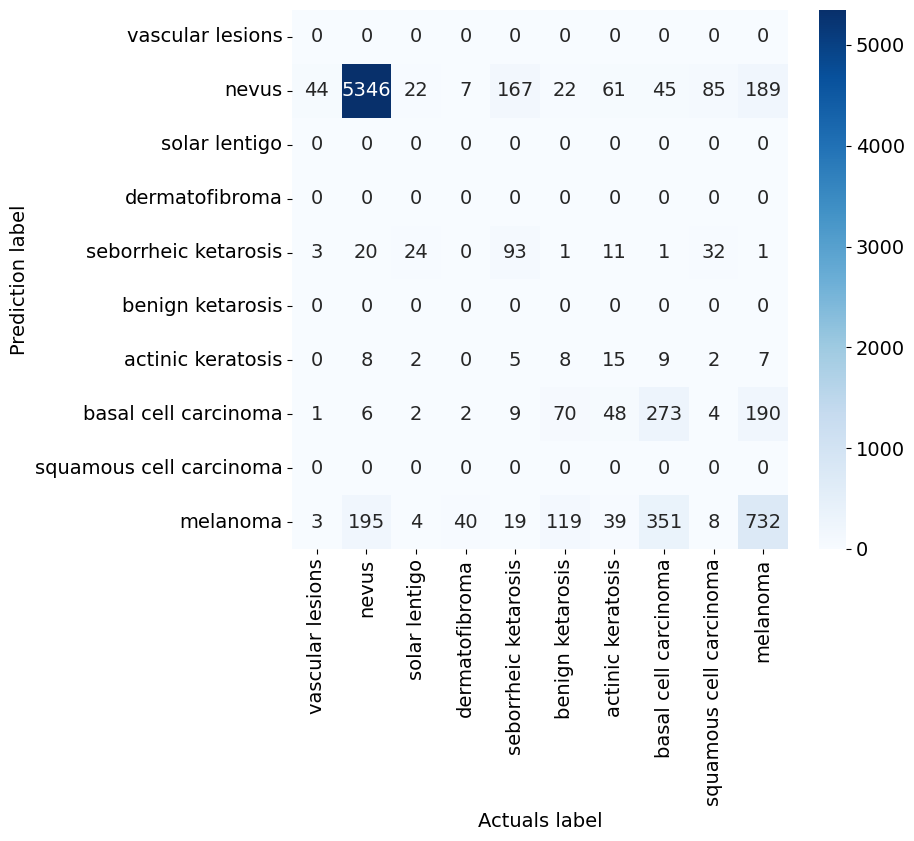

____________________________________________________________
Accuracy score: 77.40
Sensitivity: 0.7740
Specificity: 0.9749
F1: 0.7740
Matthews corrcoef: 0.5436
NPV: 0.9749
PPV: 0.7740
FNR: 0.2260
FPR: 0.0251
____________________________________________________________
Recall micro: 0.7740
Recall macro: 0.2419
Precision micro: 0.7740
Precision macro: 0.2597
F1 score micro: 0.7740
F1 score macro: 0.2426
Jaccard score micro: 0.6313
Jaccard score macro: 0.1827
Specificity macro: 0.9601
Specificity weighted: 0.8267
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7682
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9885
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9950
Specificity none - class basal cell carcinoma (7): 0.9567
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [86]:
actuals = []
predictions = []

test_NN(STUD_Model_1, testloader)

torch.save(actuals, 'STUD_Model_1\\actuals2.pt')
torch.save(predictions, 'STUD_Model_1\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_1\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.734600



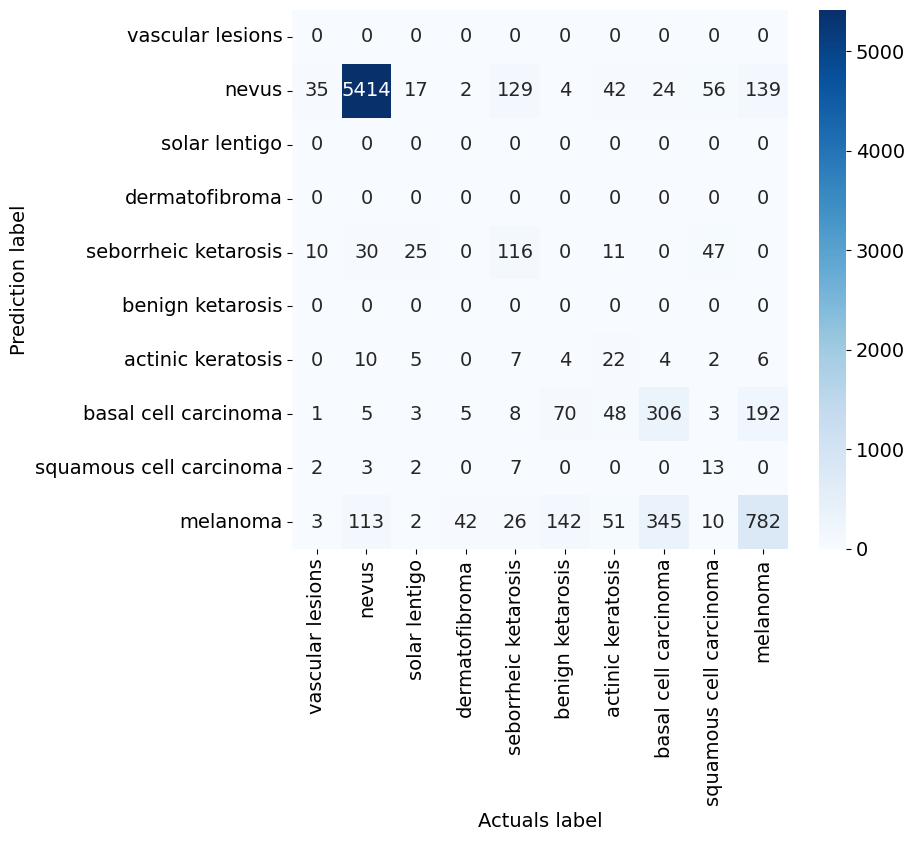

____________________________________________________________
Accuracy score: 79.72
Sensitivity: 0.7972
Specificity: 0.9775
F1: 0.7972
Matthews corrcoef: 0.5975
NPV: 0.9775
PPV: 0.7972
FNR: 0.2028
FPR: 0.0225
____________________________________________________________
Recall micro: 0.7972
Recall macro: 0.2742
Precision micro: 0.7972
Precision macro: 0.3250
F1 score micro: 0.7972
F1 score macro: 0.2793
Jaccard score micro: 0.6628
Jaccard score macro: 0.2095
Specificity macro: 0.9671
Specificity weighted: 0.8741
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8383
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9847
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9953
Specificity none - class basal cell carcinoma (7): 0.9563
Specificity none - class squamous cell carcinoma (8): 0.998

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [88]:
actuals = []
predictions = []

test_NN(STUD_Model_2, testloader)

torch.save(actuals, 'STUD_Model_2\\actuals2.pt')
torch.save(predictions, 'STUD_Model_2\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_2\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.763159



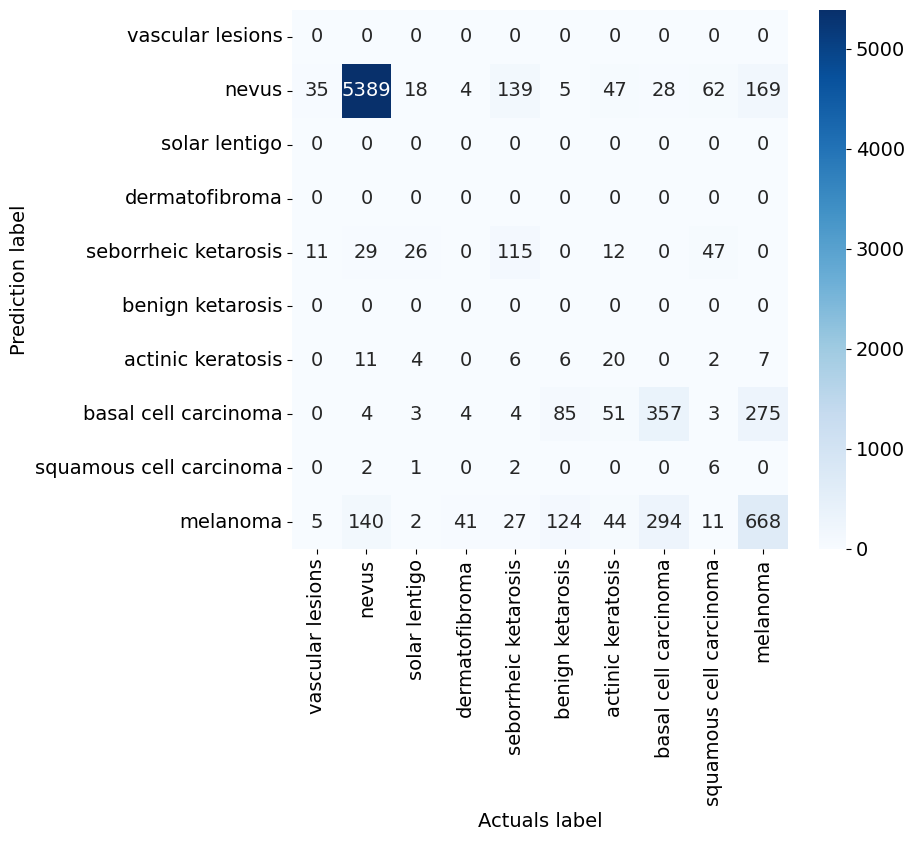

____________________________________________________________
Accuracy score: 78.55
Sensitivity: 0.7855
Specificity: 0.9762
F1: 0.7855
Matthews corrcoef: 0.5720
NPV: 0.9762
PPV: 0.7855
FNR: 0.2145
FPR: 0.0238
____________________________________________________________
Recall micro: 0.7855
Recall macro: 0.2643
Precision micro: 0.7855
Precision macro: 0.3243
F1 score micro: 0.7855
F1 score macro: 0.2657
Jaccard score micro: 0.6468
Jaccard score macro: 0.1992
Specificity macro: 0.9645
Specificity weighted: 0.8598
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8170
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9845
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9956
Specificity none - class basal cell carcinoma (7): 0.9440
Specificity none - class squamous cell carcinoma (8): 0.999

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [90]:
actuals = []
predictions = []

test_NN(STUD_Model_3, testloader)

torch.save(actuals, 'STUD_Model_3\\actuals2.pt')
torch.save(predictions, 'STUD_Model_3\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_3\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.772728



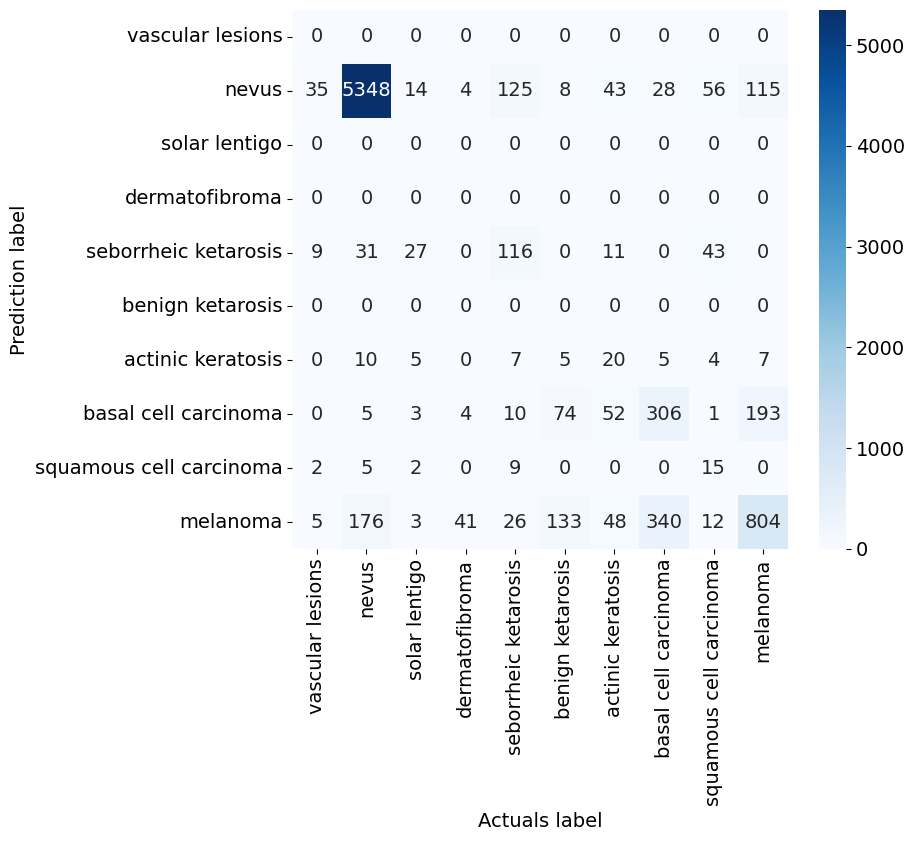

____________________________________________________________
Accuracy score: 79.20
Sensitivity: 0.7920
Specificity: 0.9769
F1: 0.7920
Matthews corrcoef: 0.5913
NPV: 0.9769
PPV: 0.7920
FNR: 0.2080
FPR: 0.0231
____________________________________________________________
Recall micro: 0.7920
Recall macro: 0.2754
Precision micro: 0.7920
Precision macro: 0.3166
F1 score micro: 0.7920
F1 score macro: 0.2787
Jaccard score micro: 0.6556
Jaccard score macro: 0.2086
Specificity macro: 0.9670
Specificity weighted: 0.8779
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8455
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9850
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9947
Specificity none - class basal cell carcinoma (7): 0.9554
Specificity none - class squamous cell carcinoma (8): 0.997

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [92]:
actuals = []
predictions = []

test_NN(STUD_Model_4, testloader)

torch.save(actuals, 'STUD_Model_4\\actuals2.pt')
torch.save(predictions, 'STUD_Model_4\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_4\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.718486



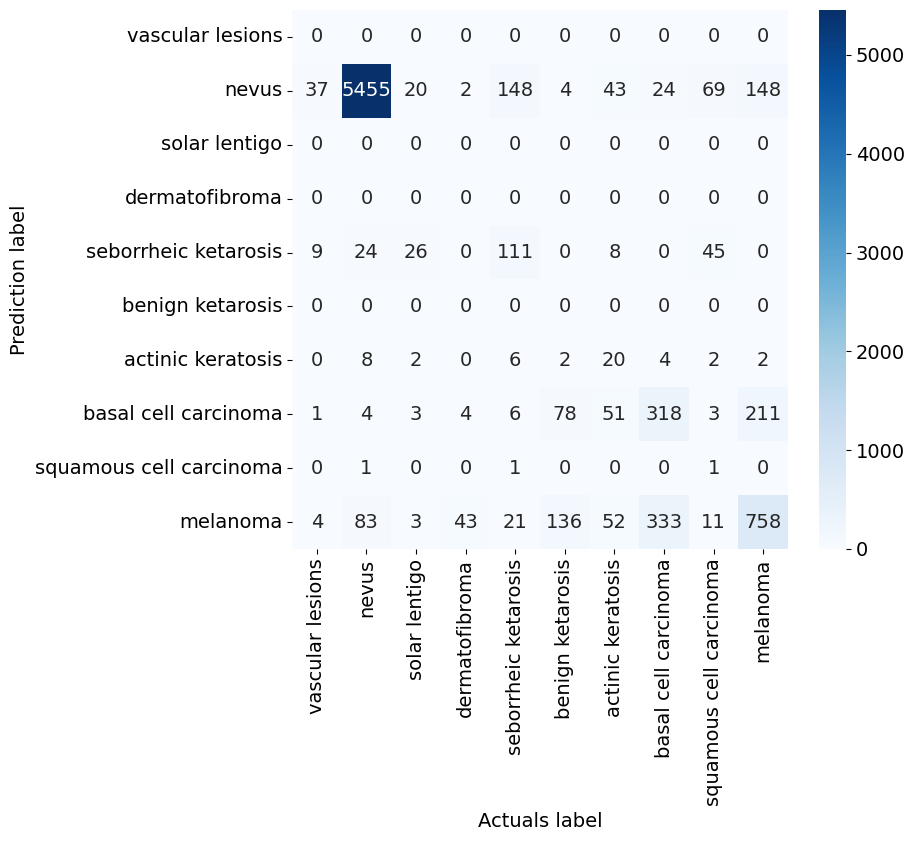

____________________________________________________________
Accuracy score: 79.84
Sensitivity: 0.7984
Specificity: 0.9776
F1: 0.7984
Matthews corrcoef: 0.5955
NPV: 0.9776
PPV: 0.7984
FNR: 0.2016
FPR: 0.0224
____________________________________________________________
Recall micro: 0.7984
Recall macro: 0.2626
Precision micro: 0.7984
Precision macro: 0.3176
F1 score micro: 0.7984
F1 score macro: 0.2633
Jaccard score micro: 0.6645
Jaccard score macro: 0.2006
Specificity macro: 0.9662
Specificity weighted: 0.8635
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8213
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9861
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9968
Specificity none - class basal cell carcinoma (7): 0.9529
Specificity none - class squamous cell carcinoma (8): 0.999

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [94]:
actuals = []
predictions = []

test_NN(STUD_Model_5, testloader)

torch.save(actuals, 'STUD_Model_5\\actuals2.pt')
torch.save(predictions, 'STUD_Model_5\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_5\\matrix2.pt')

test_metric()